# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

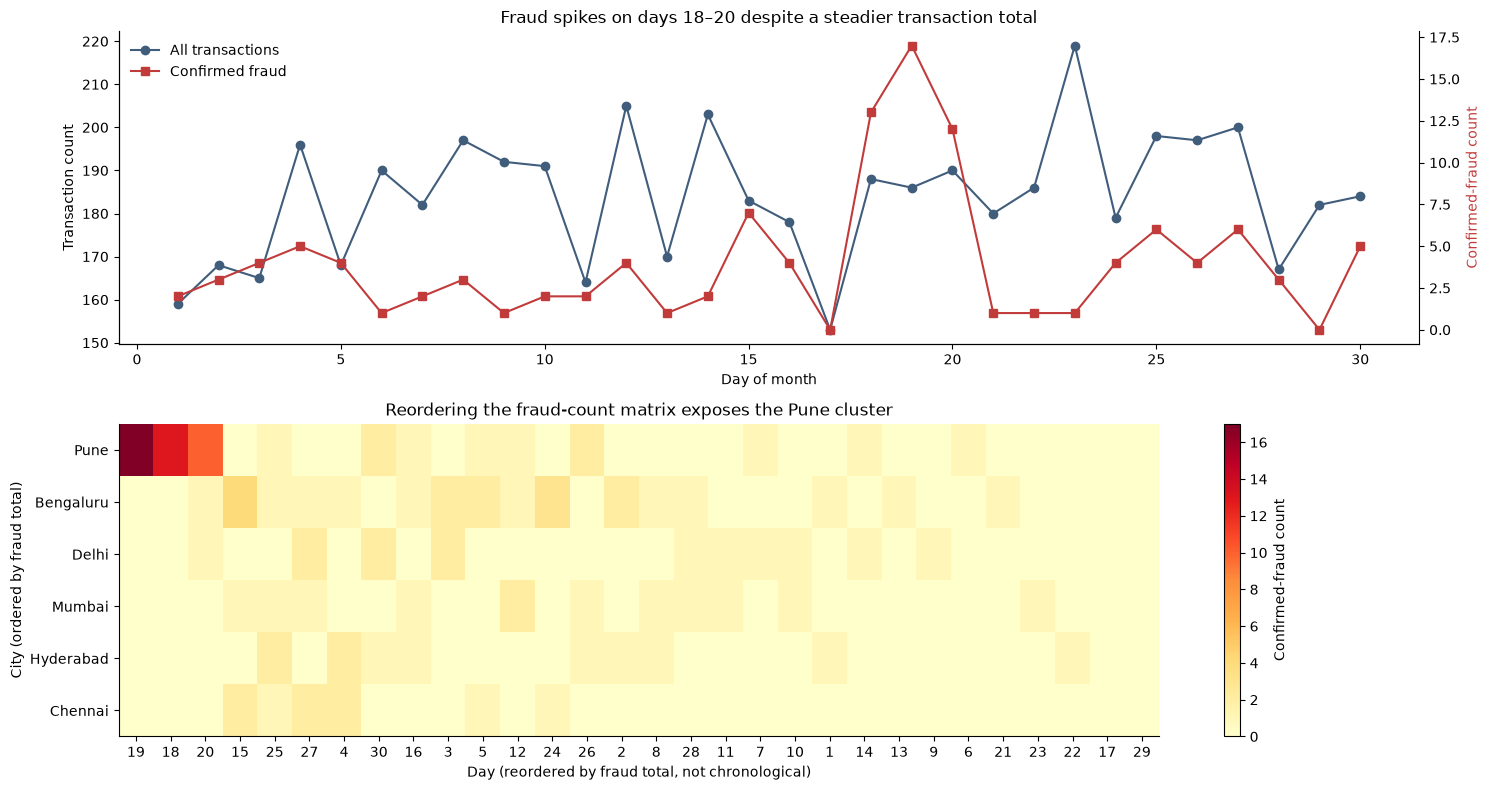

Highest-count city/day cells:


,city,day,fraud_count
0,Pune,19,17
1,Pune,18,13
2,Pune,20,10
3,Bengaluru,15,4
4,Bengaluru,24,3
5,Bengaluru,3,2
6,Pune,26,2
7,Bengaluru,2,2
8,Bengaluru,5,2
9,Pune,30,2


In [2]:
daily = tx.groupby('day').agg(transactions=('txn_id', 'size'), fraud=('is_fraud', 'sum')).reindex(range(1, 31), fill_value=0)
fig, axes = plt.subplots(2, 1, figsize=(15, 8))
line_total, = axes[0].plot(daily.index, daily.transactions, 'o-', color='#405d7c', label='All transactions')
ax_fraud = axes[0].twinx()
ax_fraud.spines['right'].set_visible(True)
line_fraud, = ax_fraud.plot(daily.index, daily.fraud, 's-', color='#c23b3b', label='Confirmed fraud')
axes[0].set(xlabel='Day of month', ylabel='Transaction count', title='Fraud spikes on days 18–20 despite a steadier transaction total')
ax_fraud.set_ylabel('Confirmed-fraud count', color='#c23b3b')
axes[0].legend(handles=[line_total, line_fraud], frameon=False, loc='upper left')

heat = tx.pivot_table(index='city', columns='day', values='is_fraud', aggfunc='sum', fill_value=0)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index,
                heat.sum(axis=0).sort_values(ascending=False).index]
mesh = axes[1].imshow(heat, cmap='YlOrRd', aspect='auto', vmin=0)
axes[1].set_xticks(np.arange(heat.shape[1]), labels=heat.columns)
axes[1].set_yticks(np.arange(heat.shape[0]), labels=heat.index)
axes[1].set(xlabel='Day (reordered by fraud total, not chronological)', ylabel='City (ordered by fraud total)',
            title='Reordering the fraud-count matrix exposes the Pune cluster')
fig.colorbar(mesh, ax=axes[1], label='Confirmed-fraud count')
plt.tight_layout(); plt.show()
print('Highest-count city/day cells:')
display(heat.stack().rename('fraud_count').sort_values(ascending=False).head(10).reset_index())

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

The chronological overview shows a short spike on days 18–20, and the reordered city × day matrix localizes its largest cells to Pune: 13, 17 and 10 confirmed cases on those days. A score-sorted alert list separates cases by model score and can hide that concentration in time and place. Reordering a matrix to reveal a pattern is the visual pattern-discovery step here; the count view suggests a hypothesis, which still needs rate-based checks against transaction exposure.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

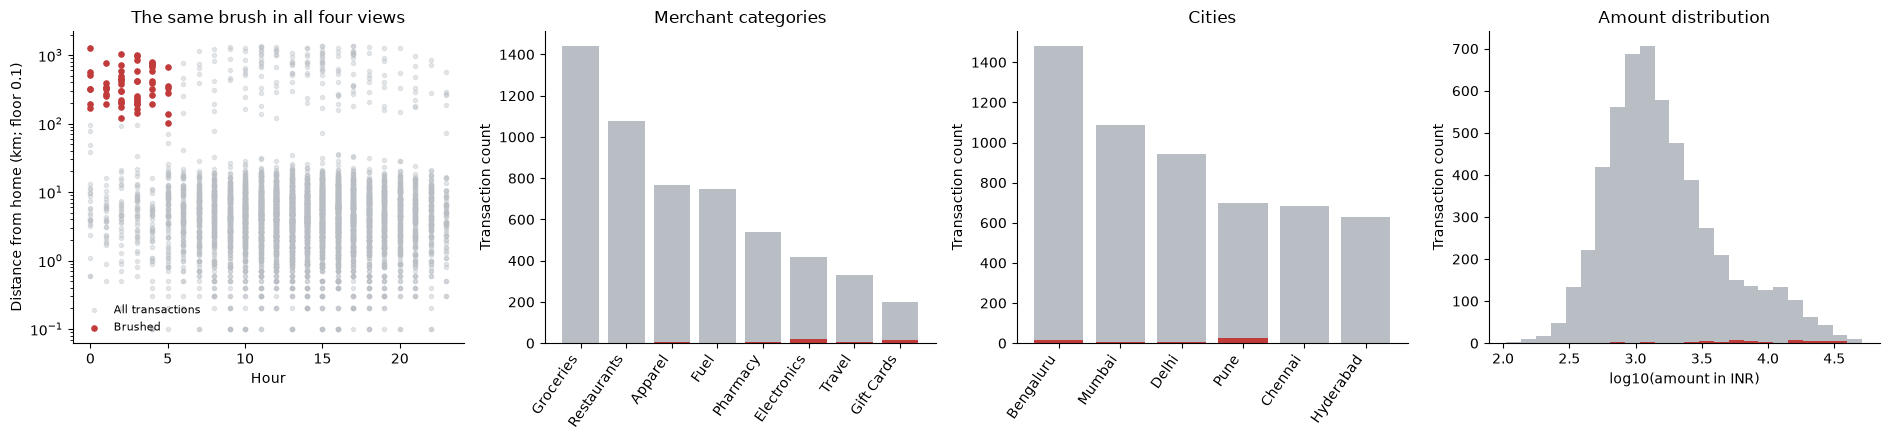

Brushed: 61; fraud rate inside 86.89%, overall 2.17%; captures 53/120 fraud = 44.17%.
Unbrushed confirmed fraud by merchant category:
merchant_category
Electronics    26
Gift Cards     24
Travel         10
Apparel         3
Pharmacy        3
Restaurants     1


In [3]:
brush = tx.night & (tx.distance_from_home_km > 100)
selected = tx.loc[brush]
fig, axes = plt.subplots(1, 4, figsize=(19, 4.5))
colors = {'all': '#b9bec4', 'brush': '#c23b3b'}
axes[0].scatter(tx.hour, np.maximum(tx.distance_from_home_km, 0.1), color=colors['all'], alpha=0.35, s=9, label='All transactions')
axes[0].scatter(selected.hour, np.maximum(selected.distance_from_home_km, 0.1), color=colors['brush'], s=14, label='Brushed')
axes[0].set(yscale='log', xlabel='Hour', ylabel='Distance from home (km; floor 0.1)', title='The same brush in all four views')
axes[0].legend(frameon=False, fontsize=8)
for ax, column, title in [(axes[1], 'merchant_category', 'Merchant categories'), (axes[2], 'city', 'Cities')]:
    counts = tx[column].value_counts()
    highlighted = selected[column].value_counts().reindex(counts.index, fill_value=0)
    positions = np.arange(len(counts))
    ax.bar(positions, counts, color=colors['all'])
    ax.bar(positions, highlighted, color=colors['brush'])
    ax.set_xticks(positions, counts.index, rotation=55, ha='right')
    ax.set(title=title, ylabel='Transaction count')
log_amount = np.log10(tx.amount_inr)
bins = np.linspace(log_amount.min(), log_amount.max(), 25)
axes[3].hist(log_amount, bins=bins, color=colors['all'])
axes[3].hist(np.log10(selected.amount_inr), bins=bins, color=colors['brush'])
axes[3].set(xlabel='log10(amount in INR)', ylabel='Transaction count', title='Amount distribution')
plt.tight_layout(); plt.show()
brush_count = int(brush.sum())
brush_rate = selected.is_fraud.mean()
overall_rate = tx.is_fraud.mean()
brush_capture = selected.is_fraud.sum() / tx.is_fraud.sum()
print(f'Brushed: {brush_count}; fraud rate inside {brush_rate:.2%}, overall {overall_rate:.2%}; '
      f'captures {selected.is_fraud.sum()}/{tx.is_fraud.sum()} fraud = {brush_capture:.2%}.')
print('Unbrushed confirmed fraud by merchant category:')
print(tx.loc[~brush & tx.is_fraud.eq(1), 'merchant_category'].value_counts().to_string())

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

The brush contains 61 transactions, of which 53 are fraud: an 86.89% fraud rate compared with 2.17% overall. However, it captures only 53 of 120 confirmed cases (44.17%), so relying on it alone misses 67 cases and cannot replace a broader detector. The category view suggests checking Electronics and Gift Cards beyond their red subsets; the printed breakdown verifies 26 and 24 unbrushed confirmed fraud cases in those categories respectively, rather than assuming every grey transaction is fraudulent.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)
elapsed = []
for _ in range(5):
    start = time.perf_counter()
    result = big.loc[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    elapsed.append(time.perf_counter() - start)
best_s = min(elapsed)
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (best_s / len(big))
t_50m = best_s * 50_000_000 / len(big)
skip_pct = max(0, 1 - 0.1 / t_50m) * 100
print(f'{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s')
print(f'50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s')
print('Five runs (ms):', [round(s * 1000, 2) for s in elapsed])
print('Linear, in-memory extrapolation only: excludes network, browser rendering and larger-table memory effects.')
del big, result

1,004,640 rows in 13.1 ms -> 0.0130 us/row -> max 7,669,341 rows in 0.1 s
50M rows -> 0.65 s; must skip 84.7% of rows to stay under 0.1 s
Five runs (ms): [20.94, 16.06, 13.83, 13.1, 13.88]
Linear, in-memory extrapolation only: excludes network, browser rendering and larger-table memory effects.


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

Pre-aggregate transactions into score, time, city and amount bins, then let the slider query those much smaller summaries. That reduce technique preserves counts and approximate distributions but loses individual case details and can conceal narrow clusters inside a bin; investigators should be able to drill down to the exact transactions after selecting a region. The measured filter time is only part of the 0.1 s interaction budget, which must also cover data transfer and drawing.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

,threshold,alerts,TP,FP,FN,precision,recall,F1
0,0.05,2012,114,1898,6,0.056660,0.950000,0.106942
1,0.10,1167,111,1056,9,0.095116,0.925000,0.172494
2,0.15,786,110,676,10,0.139949,0.916667,0.242826
3,0.20,596,106,490,14,0.177852,0.883333,0.296089
4,0.25,471,105,366,15,0.222930,0.875000,0.355330
5,0.30,401,104,297,16,0.259352,0.866667,0.399232
6,0.35,355,104,251,16,0.292958,0.866667,0.437895
7,0.40,319,104,215,16,0.326019,0.866667,0.473804
8,0.45,283,104,179,16,0.367491,0.866667,0.516129
9,0.50,260,101,159,19,0.388462,0.841667,0.531579


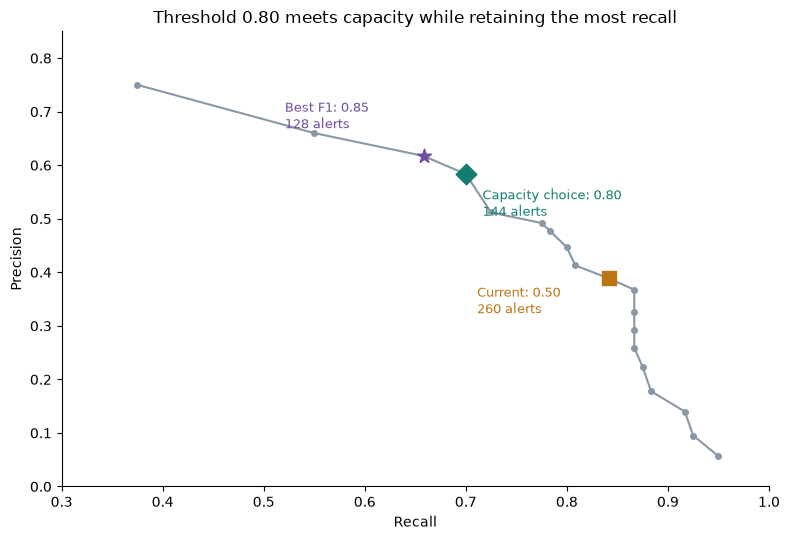

Recommend threshold 0.80: 144 alerts ≤150; precision 58.33%, recall 70.00%, 84 TP, 60 FP, 36 missed fraud.
Best F1 occurs at 0.85: F1=0.6371.


In [5]:
rows = []
truth = tx.is_fraud.eq(1)
for threshold in np.arange(1, 20) / 20:
    flagged_mask = tx.detector_score >= threshold
    tp = int((flagged_mask & truth).sum())
    fp = int((flagged_mask & ~truth).sum())
    fn = int((~flagged_mask & truth).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    rows.append(dict(threshold=threshold, alerts=int(flagged_mask.sum()), TP=tp, FP=fp, FN=fn,
                     precision=precision, recall=recall, F1=f1))
pr = pd.DataFrame(rows)
capacity_choice = pr.loc[pr.alerts <= 150].sort_values(['recall', 'precision'], ascending=False).iloc[0]
best_f1 = pr.loc[pr.F1.idxmax()]
current = pr.loc[np.isclose(pr.threshold, 0.5)].iloc[0]
display(pr)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(pr.recall, pr.precision, 'o-', color='#8997a6', ms=4)
for row, color, marker, label, offset in [
    (current, '#bb7515', 's', 'Current', (-95, -25)),
    (capacity_choice, '#147d71', 'D', 'Capacity choice', (12, -30)),
    (best_f1, '#704ca3', '*', 'Best F1', (-100, 20))]:
    ax.scatter(row.recall, row.precision, c=color, marker=marker, s=110, zorder=3)
    ax.annotate(f'{label}: {row.threshold:.2f}\n{int(row.alerts)} alerts',
                (row.recall, row.precision), xytext=offset, textcoords='offset points', color=color, fontsize=9)
ax.set(xlim=(0.3, 1), ylim=(0, 0.85), xlabel='Recall', ylabel='Precision',
       title='Threshold 0.80 meets capacity while retaining the most recall')
plt.tight_layout(); plt.show()
print(f'Recommend threshold {capacity_choice.threshold:.2f}: {int(capacity_choice.alerts)} alerts ≤150; '
      f'precision {capacity_choice.precision:.2%}, recall {capacity_choice.recall:.2%}, '
      f'{int(capacity_choice.TP)} TP, {int(capacity_choice.FP)} FP, {int(capacity_choice.FN)} missed fraud.')
print(f'Best F1 occurs at {best_f1.threshold:.2f}: F1={best_f1.F1:.4f}.')

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

The Head of Fraud Ops should own the final decision with investigators and model engineers because the tradeoff includes review capacity, the cost of missed fraud and the harm of investigating legitimate customers. On this month, 0.80 gives the highest recall within 150 alerts, whereas 0.85 slightly improves F1 by sacrificing recall; neither metric decides those operational priorities on its own. Human-in-the-loop visual analytics makes the alternatives and their consequences visible, and the choice should be monitored on future data because these labels were also used to evaluate the threshold.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
flagged = tx.loc[tx.detector_score >= 0.3].copy()
scatter = px.scatter(flagged, x='timestamp', y='amount_inr', color='label', log_y=True,
                     color_discrete_map={'confirmed fraud': '#c23b3b', 'legitimate': '#8794a3'},
                     hover_data=['txn_id', 'customer_id', 'city', 'merchant_category',
                                 'distance_from_home_km', 'detector_score'],
                     title=f'{len(flagged)} cases at score ≥0.30 • select, zoom and hover for details',
                     labels={'amount_inr': 'Amount (INR)', 'timestamp': 'Transaction time'})
scatter.update_layout(dragmode='select', legend_title_text='Confirmed outcome')
scatter.show()

# Pre-aggregating counts and fraud totals produces correctly weighted parent rates.
drill = tx.groupby(['city', 'merchant_category'], as_index=False).agg(
    count=('txn_id', 'size'), fraud_count=('is_fraud', 'sum'))
drill['fraud_rate'] = drill.fraud_count / drill['count']
sunburst = px.sunburst(drill, path=['city', 'merchant_category'], values='count', color='fraud_rate',
                      color_continuous_scale='YlOrRd', range_color=(0, drill.fraud_rate.max()),
                      hover_data=['count'],
                      title='Whole-month drill-down • city → merchant category; color = fraud rate')
sunburst.update_layout(coloraxis_colorbar_tickformat='.0%')
sunburst.update_traces(hovertemplate='<b>%{label}</b><br>Transactions: %{value}<br>Fraud rate: %{color:.2%}<extra></extra>')
sunburst.show()

# A self-contained browser version preserves interactivity outside notebook viewers.
from pathlib import Path
import plotly.io as pio
html = '<!doctype html><html><head><meta charset="utf-8"><title>Fraud investigation views</title></head><body>'
html += scatter.to_html(full_html=False, include_plotlyjs=True)
html += sunburst.to_html(full_html=False, include_plotlyjs=False)
html += '</body></html>'
Path('unit3_ppt7_interactive_views.html').write_text(html, encoding='utf-8')
print('Saved unit3_ppt7_interactive_views.html (self-contained). Selection highlights cases within the scatter; '
      'Task 2 demonstrates the fixed brush across four views.')

Saved unit3_ppt7_interactive_views.html (self-contained). Selection highlights cases within the scatter; Task 2 demonstrates the fixed brush across four views.


**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

Hovering through all 401 cases requires repeated pointing and asks the investigator to remember previous tooltips, making month-wide patterns hard to compare. The daily overview and reordered city × day heatmap reveal the time/place cluster at once, and the sunburst summarizes category composition before drilling down. Tooltips then supply details on demand for a few selected transactions rather than serving as the overview.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Exploratory hypothesis: confirmed fraud is concentrated in Pune on days 18–20, beyond its normal rate and the rate in other cities on those days.
Inside: 37.38%; outside: 1.48%; chi²=619.29, df=1, p=1.06e-136; minimum expected cell=2.33


is_fraud,Legitimate,Fraud
row_0,,
Outside window,5333,80
"Pune, days 18–20",67,40


,group,transactions,fraud,rate
0,"Pune, days 18–20",107,40,0.373832
1,"Pune, other days",593,11,0.018550
2,"Other cities, days 18–20",457,2,0.004376
3,"Other cities, other days",4363,67,0.015356


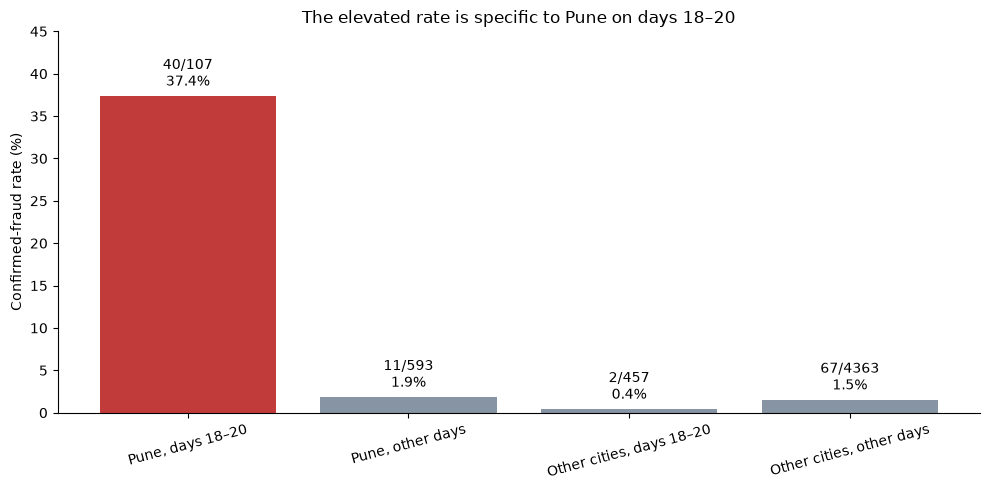

Fisher exact sensitivity check: odds ratio 39.80, p=3.55e-41.
Verdict: a localized fraud-rate cluster is supported; an organized ring is not proven. The window was selected after viewing the data, so p-values are exploratory, and repeat customers or correlated cases can violate transaction independence. Investigate shared customer/merchant/device evidence before attributing a ring.


In [7]:
from scipy.stats import chi2_contingency
hypothesis_city = 'Pune'
hypothesis_days = (18, 20)
print('Exploratory hypothesis: confirmed fraud is concentrated in Pune on days 18–20, '
      'beyond its normal rate and the rate in other cities on those days.')
same_city = tx.city.eq(hypothesis_city)
same_days = tx.day.between(*hypothesis_days)
in_window = same_city & same_days
contingency = pd.crosstab(in_window, tx.is_fraud)
chi2, p_value, dof, expected = chi2_contingency(contingency)
inside_rate = tx.loc[in_window, 'is_fraud'].mean()
outside_rate = tx.loc[~in_window, 'is_fraud'].mean()
print(f'Inside: {inside_rate:.2%}; outside: {outside_rate:.2%}; '
      f'chi²={chi2:.2f}, df={dof}, p={p_value:.3g}; minimum expected cell={expected.min():.2f}')
display(contingency.rename(index={False: 'Outside window', True: 'Pune, days 18–20'},
                            columns={0: 'Legitimate', 1: 'Fraud'}))
groups = {'Pune, days 18–20': in_window, 'Pune, other days': same_city & ~same_days,
          'Other cities, days 18–20': ~same_city & same_days, 'Other cities, other days': ~same_city & ~same_days}
comparison = pd.DataFrame([
    {'group': name, 'transactions': int(mask.sum()), 'fraud': int(tx.loc[mask, 'is_fraud'].sum()),
     'rate': tx.loc[mask, 'is_fraud'].mean()} for name, mask in groups.items()])
display(comparison)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(comparison.group, 100 * comparison.rate, color=['#c23b3b', '#8794a3', '#8794a3', '#8794a3'])
ax.bar_label(bars, labels=[f'{r.fraud}/{r.transactions}\n{r.rate:.1%}' for r in comparison.itertuples()], padding=4)
ax.set(ylim=(0, 45), ylabel='Confirmed-fraud rate (%)', title='The elevated rate is specific to Pune on days 18–20')
ax.tick_params(axis='x', labelrotation=15)
plt.tight_layout(); plt.show()
# The expected fraud count in the small window is <5: supplement the requested chi-square.
from scipy.stats import fisher_exact
odds_ratio, fisher_p = fisher_exact(contingency)
print(f'Fisher exact sensitivity check: odds ratio {odds_ratio:.2f}, p={fisher_p:.3g}.')
print('Verdict: a localized fraud-rate cluster is supported; an organized ring is not proven. '
      'The window was selected after viewing the data, so p-values are exploratory, '
      'and repeat customers or correlated cases can violate transaction independence. '
      'Investigate shared customer/merchant/device evidence before attributing a ring.')

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

If Pune had a similarly high fraud rate on the other days, the narrow 18–20-day hypothesis would be weakened and a persistent city-specific issue, customer mix or labeling difference would be a better explanation. If other cities had also spiked on days 18–20, that counterexample would favor a system-wide campaign, detector change or processing issue over a Pune-only event. Both checks came out much lower here, but that supports localization rather than proving coordination between offenders.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

The month contains 5,520 transactions and 120 confirmed fraud cases (2.17%), including 40 fraud among 107 Pune transactions on days 18–20 (37.38%), a localized cluster that warrants investigation but does not prove a ring. I recommend an initial threshold of 0.80, chosen with the Head of Fraud Ops: its 144 alerts fit the 150-case capacity, with 58.33% precision and 70.00% recall, leaving 36 confirmed cases unflagged. The best-F1 threshold of 0.85 reduces the workload further but also reduces recall, so the human decision should reflect the costs of missed cases and false alerts. I would build the time-versus-amount interactive scatter first, opening on the whole flagged period and supporting selection, zoom and details-on-demand for individual cases, with pre-aggregated summaries for large-history dynamic queries. The night/far-away brush is useful for prioritization but captures only 44.17% of fraud, so it must not become the sole rule. Add an investigator-label feedback loop in which reviewed outcomes and corrections feed detector retraining, followed by validation on a later held-out month and monitoring of precision, recall and review workload.